In [2]:
# Theory

# Regression learns relationships between input features and a target variable. Simple linear
# regression uses one feature and fits a straight line: y = b0 + b1*x. The intercept b0 is the
# prediction at zero input, and b1 represents the slope. Multiple linear regression uses several
# features: y = b0 + b1*x1 + b2*x2 + ... . Linear regression fits coefficients by minimizing the
# sum of squared training errors. Here, both numerical models use the same split so their test
# results can be compared. The simple model uses one feature, while the multiple model uses all
# three features.

# MAE measures the average absolute prediction error in the units of the target. MSE averages
# squared errors and therefore gives greater weight to large mistakes. RMSE is the square root
# of MSE and has the same units as the target. R2 measures improvement over predicting the test-
# target mean and can be negative. An actual-versus-predicted plot shows agreement; ideal
# predictions lie on y = x.

# Logistic regression is a classification algorithm despite having regression in its name. It
# estimates class probabilities and assigns a class, here one of three Iris species. A pipeline
# learns feature scaling from training data before fitting logistic regression. Accuracy
# measures the fraction of correct predictions on the unseen test set. A confusion matrix shows
# which actual classes were assigned to each predicted class. Precision, recall and F1 provide
# additional measures of classification performance. Regression is useful for price forecasting;
# classification is useful for diagnosis and labeling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# Create numerical data for simple and multiple regression
X, y = make_regression(n_samples=100, n_features=3, noise=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


 Simple Linear Regression
Coefficients: [19.23134117]
Intercept: 5.533647193685297
MAE: 59.11309349896841
MSE: 7179.994867366317
RMSE: 84.73485037082627
R2 Score: -0.042105351841573935

 Multiple Linear Regression
Coefficients: [28.49475136 74.39534965 18.78132401]
Intercept: 1.3037594527225016
MAE: 8.960994532577917
MSE: 123.84680824798075
RMSE: 11.128648087165878
R2 Score: 0.9820248587822378


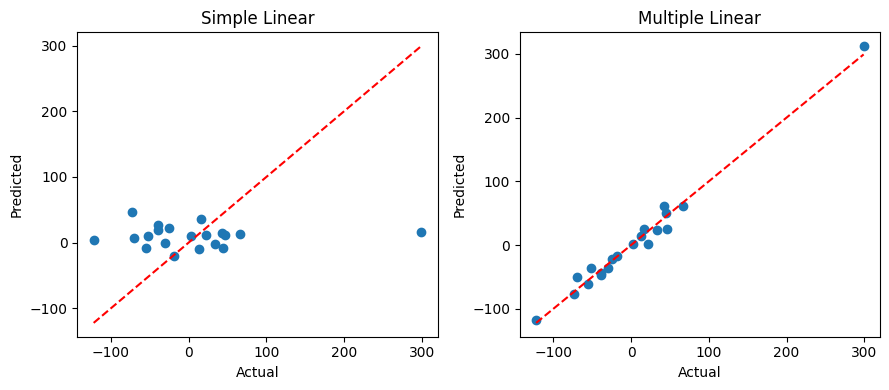

In [4]:
# Simple regression uses one input; multiple regression uses all three
plt.figure(figsize=(9, 4))
for name, columns in [('Simple Linear', [0]), ('Multiple Linear', [0, 1, 2])]:
    model = LinearRegression()
    model.fit(X_train[:, columns], y_train)
    prediction = model.predict(X_test[:, columns])
    print("\n", name, "Regression")
    print("Coefficients:", model.coef_)
    print("Intercept:", model.intercept_)
    print("MAE:", mean_absolute_error(y_test, prediction))
    print("MSE:", mean_squared_error(y_test, prediction))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, prediction)))
    print("R2 Score:", r2_score(y_test, prediction))
    plt.subplot(1, 2, len(columns) // 2 + 1)
    plt.scatter(y_test, prediction)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.title(name)
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
plt.tight_layout()
plt.show()

In [5]:
# Logistic regression predicts flower classes
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42, stratify=iris.target)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=200))
model.fit(X_train, y_train)
prediction = model.predict(X_test)
print("\nLogistic Regression Accuracy:", accuracy_score(y_test, prediction) * 100)
print("Confusion Matrix:\n", confusion_matrix(y_test, prediction))
print(classification_report(y_test, prediction, target_names=iris.target_names))
print("First five predictions:", prediction[:5])
print("Actual classes:", y_test[:5])


Logistic Regression Accuracy: 93.33333333333333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

First five predictions: [0 2 1 1 0]
Actual classes: [0 2 1 1 0]
